# LoRA Fine-tuning từ con số 0

Notebook này dành cho người **chưa biết gì về LoRA**. Chúng ta đi từ trực giác → toán → tự code LoRA bằng PyTorch thuần → fine-tune một mô hình ngôn ngữ thật (DistilGPT-2) → so sánh với thư viện `peft` mà người ta dùng trong thực tế.

**Lộ trình**

| Phần | Nội dung | Câu hỏi trả lời |
|---|---|---|
| 0 | Chuẩn bị môi trường | |
| 1 | Fine-tuning là gì & vì sao nó đắt | Tại sao cần LoRA? |
| 2 | Hạng (rank) của ma trận & SVD | "Low-rank" nghĩa là gì? |
| 3 | Toán của LoRA | LoRA làm chính xác điều gì? |
| 4 | Tự code `LoRALayer` | Cài đặt trong ~30 dòng |
| 5 | Thí nghiệm đồ chơi | Rank `r` ảnh hưởng thế nào? |
| 6 | Fine-tune DistilGPT-2 bằng LoRA tự viết | Dùng trên LLM thật ra sao? |
| 7 | Làm lại với thư viện `peft` | Thực tế người ta viết thế nào? |
| 8 | Siêu tham số, QLoRA, các biến thể, lỗi hay gặp | Áp dụng cho model lớn |
| 9 | Bài tập & tài liệu | Học tiếp ở đâu? |

> Kiến thức cần có: Python, một chút PyTorch (tensor, `nn.Module`, `loss.backward()`), nhân ma trận.

## Phần 0 — Chuẩn bị môi trường

Cần: `torch`, `transformers`, `peft`, `matplotlib`. Trong repo này đã có sẵn `.venv`:

```bash
uv venv --python 3.12 .venv
uv pip install --python .venv/bin/python torch transformers peft matplotlib ipykernel
```

Rồi chọn kernel `.venv` trong VS Code. Notebook chạy được trên CPU, Apple Silicon (MPS) hoặc GPU NVIDIA (CUDA).

In [1]:
import math, os, time, copy
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print("torch", torch.__version__, "| device:", device)

Matplotlib is building the font cache; this may take a moment.


torch 2.14.1 | device: mps


## Phần 1 — Fine-tuning là gì và vì sao nó đắt?

### 1.1 Pre-training vs Fine-tuning
- **Pre-training**: huấn luyện mô hình trên lượng dữ liệu khổng lồ (hàng nghìn tỷ token) để học ngôn ngữ "chung chung". Rất đắt — chỉ các công ty lớn làm.
- **Fine-tuning**: lấy mô hình đã pre-train, huấn luyện **tiếp** trên dữ liệu nhỏ, chuyên biệt (ví dụ: chat theo phong cách công ty, trả lời về tài liệu nội bộ, phân loại email…).

Mô hình neural network về bản chất là một đống **ma trận trọng số** $W$. Fine-tuning = cập nhật các ma trận này:

$$W_{\text{mới}} = W_{\text{cũ}} + \Delta W$$

### 1.2 Full fine-tuning: cập nhật **toàn bộ** $W$
Vấn đề là bộ nhớ. Khi train bằng optimizer Adam (fp32), **mỗi tham số** cần:

| Thứ cần lưu | Byte / tham số |
|---|---|
| Trọng số (fp32) | 4 |
| Gradient | 4 |
| Adam: moment bậc 1 ($m$) | 4 |
| Adam: moment bậc 2 ($v$) | 4 |
| **Tổng** (chưa tính activation) | **16** |

Hãy tính thử cho vài kích thước mô hình:

In [2]:
def full_ft_memory_gb(n_params, bytes_per_param=16):
    return n_params * bytes_per_param / 1e9

for name, n in [("DistilGPT-2", 82e6), ("Llama-3 8B", 8e9), ("Llama-3 70B", 70e9)]:
    print(f"{name:12s}: {n/1e9:6.2f}B tham số -> full fine-tune cần ~{full_ft_memory_gb(n):7.1f} GB (chưa tính activation)")

DistilGPT-2 :   0.08B tham số -> full fine-tune cần ~    1.3 GB (chưa tính activation)
Llama-3 8B  :   8.00B tham số -> full fine-tune cần ~  128.0 GB (chưa tính activation)
Llama-3 70B :  70.00B tham số -> full fine-tune cần ~ 1120.0 GB (chưa tính activation)


Một mô hình 8B cần ~128 GB chỉ để full fine-tune — vượt xa một GPU 24 GB. Ngoài ra, mỗi tác vụ lại sinh ra **một bản sao đầy đủ** của mô hình (16 GB cho 8B ở fp16): 10 khách hàng = 10 bản sao.

### 1.3 Ý tưởng của PEFT (Parameter-Efficient Fine-Tuning)
**Đóng băng (freeze)** gần như toàn bộ mô hình gốc, chỉ train một lượng **rất nhỏ** tham số mới. Gradient và trạng thái Adam chỉ cần cho phần nhỏ đó → tiết kiệm bộ nhớ khổng lồ.

**LoRA (Low-Rank Adaptation, Hu et al., 2021)** là phương pháp PEFT phổ biến nhất. Để hiểu nó, ta cần khái niệm **hạng (rank)** của ma trận.

## Phần 2 — Hạng của ma trận (rank) và "low-rank"

### 2.1 Trực giác
Ma trận $M$ kích thước $d \times d$ có $d^2$ số. Nhưng nếu $M$ có thể viết dưới dạng **tích của hai ma trận mỏng**:

$$M = B \cdot A, \quad B \in \mathbb{R}^{d \times r},\; A \in \mathbb{R}^{r \times d},\; r \ll d$$

thì ta chỉ cần lưu $2 \cdot d \cdot r$ số thay vì $d^2$. Ma trận như vậy gọi là có **hạng ≤ r** ("low-rank").

Ví dụ $d = 4096$, $r = 8$: $d^2 \approx 16.8$ triệu số, còn $2dr = 65{,}536$ số — **nhỏ hơn 256 lần**.

Ý nghĩa hình học: $M$ có hạng $r$ nghĩa là mọi output $Mx$ đều nằm trong một không gian con chỉ có $r$ chiều. Ma trận "trông thì to" nhưng thông tin thực sự chỉ có $r$ "hướng".

In [3]:
d, r = 4096, 8
B = torch.randn(d, r)
A = torch.randn(r, d)
M = B @ A                        # ma trận 4096 x 4096
print("Kích thước M:", tuple(M.shape))
print("Hạng thực sự của M:", torch.linalg.matrix_rank(M).item())
print(f"Số phần tử M = {M.numel():,}  vs  B + A = {B.numel() + A.numel():,}  (nhỏ hơn {M.numel() / (B.numel() + A.numel()):.0f} lần)")

Kích thước M: (4096, 4096)


Hạng thực sự của M: 8
Số phần tử M = 16,777,216  vs  B + A = 65,536  (nhỏ hơn 256 lần)


### 2.2 SVD — công cụ để "đo" một ma trận gần low-rank đến đâu
Mọi ma trận đều phân tích được bằng **SVD** (Singular Value Decomposition):

$$M = U \Sigma V^\top = \sum_{i} \sigma_i \, u_i v_i^\top$$

- $\sigma_1 \ge \sigma_2 \ge \dots \ge 0$ là các **giá trị kỳ dị (singular values)** — độ "quan trọng" của từng hướng.
- Giữ lại $k$ thành phần lớn nhất cho ta **xấp xỉ hạng $k$ tốt nhất** (định lý Eckart–Young).

Ma trận thực tế hiếm khi *chính xác* low-rank, nhưng thường **gần** low-rank: vài $\sigma_i$ đầu rất lớn, phần còn lại nhỏ (như nhiễu). Hãy tạo một ma trận như vậy:

Hạng (số học) của M: 512 — đầy đủ, vì có nhiễu


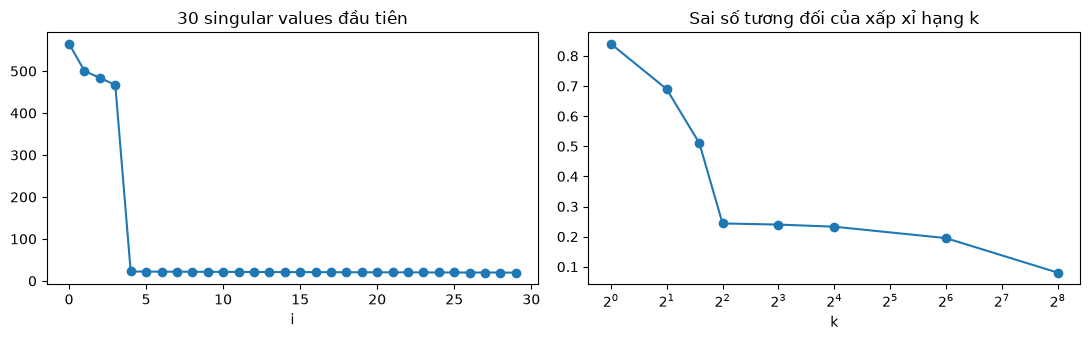

k=  1: sai số 0.840, số tham số   1,024 / 262,144
k=  2: sai số 0.690, số tham số   2,048 / 262,144
k=  3: sai số 0.510, số tham số   3,072 / 262,144
k=  4: sai số 0.244, số tham số   4,096 / 262,144
k=  8: sai số 0.240, số tham số   8,192 / 262,144
k= 16: sai số 0.233, số tham số  16,384 / 262,144
k= 64: sai số 0.195, số tham số  65,536 / 262,144
k=256: sai số 0.081, số tham số 262,144 / 262,144


In [4]:
torch.manual_seed(0)
d = 512
M = torch.randn(d, 4) @ torch.randn(4, d) + 0.5 * torch.randn(d, d)   # "tín hiệu" hạng 4 + nhiễu

U, S, Vh = torch.linalg.svd(M)
print("Hạng (số học) của M:", torch.linalg.matrix_rank(M).item(), "— đầy đủ, vì có nhiễu")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(S[:30].numpy(), "o-"); ax[0].set_title("30 singular values đầu tiên"); ax[0].set_xlabel("i")
errs = []
ks = [1, 2, 3, 4, 8, 16, 64, 256]
for k in ks:
    Mk = U[:, :k] @ torch.diag(S[:k]) @ Vh[:k]
    errs.append(((M - Mk).norm() / M.norm()).item())
ax[1].plot(ks, errs, "o-"); ax[1].set_xscale("log", base=2)
ax[1].set_title("Sai số tương đối của xấp xỉ hạng k"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()
for k, e in zip(ks, errs):
    print(f"k={k:3d}: sai số {e:.3f}, số tham số {2*d*k:>7,} / {d*d:,}")

**Quan sát:** 4 giá trị kỳ dị đầu vượt trội; sau $k=4$ sai số giảm rất chậm (phần còn lại chỉ là nhiễu). Tức là với 4 "hướng" ta đã nắm gần hết thông tin có cấu trúc.

### 2.3 Giả thuyết cốt lõi của LoRA
> Khi fine-tune, **phần thay đổi** $\Delta W$ của trọng số có **"hạng nội tại" (intrinsic rank) thấp**.

Trực giác: mô hình pre-train đã biết rất nhiều; để thích nghi với một tác vụ cụ thể, nó chỉ cần điều chỉnh theo **một vài hướng**, không phải viết lại toàn bộ ma trận. Bài báo LoRA kiểm chứng thực nghiệm: với GPT-3 175B, $r$ = 1–8 đã đạt chất lượng ngang full fine-tune trên nhiều tác vụ.

Vậy thay vì học $\Delta W$ đầy đủ ($d \times k$ số), ta **ép** nó có dạng low-rank $\Delta W = BA$ và chỉ học $A$, $B$.

### 🎬 Xem clip trước (92 giây)
Clip hoạt hình minh họa toàn bộ cơ chế LoRA: [media/lora_explained.mp4](media/lora_explained.mp4) (tạo lại bằng `.venv/bin/python media/make_lora_clip.py`).

<video src="media/lora_explained.mp4" controls width="720"></video>

## Phần 3 — Toán của LoRA

### 3.1 Công thức
Xét một lớp tuyến tính với trọng số pre-train $W_0 \in \mathbb{R}^{d_{out} \times d_{in}}$. Bình thường: $h = W_0 x$.

LoRA thay bằng:

$$\boxed{h = W_0 x + \frac{\alpha}{r} \, B A x}$$

| Ký hiệu | Kích thước | Train? | Khởi tạo |
|---|---|---|---|
| $W_0$ | $d_{out} \times d_{in}$ | ❌ đóng băng | trọng số pre-train |
| $A$ | $r \times d_{in}$ | ✅ | ngẫu nhiên (Kaiming / Gaussian) |
| $B$ | $d_{out} \times r$ | ✅ | **toàn số 0** |
| $r$ | số nguyên (4, 8, 16, …) | siêu tham số | "rank" |
| $\alpha$ | số thực | siêu tham số | hệ số scale ("lora_alpha") |

```
            x  (d_in)
            │
     ┌──────┴───────┐
     ▼              ▼
 ┌────────┐     ┌───────┐
 │  W0    │     │   A   │  r × d_in   (nén xuống r chiều)
 │(frozen)│     └───┬───┘
 │        │         ▼
 │        │     ┌───────┐
 │        │     │   B   │  d_out × r  (bung ra lại d_out)
 └───┬────┘     └───┬───┘
     │              │ × α/r
     └────(+)───────┘
           ▼
           h  (d_out)
```

### 3.2 Tại sao từng chi tiết lại như vậy?

**(a) Vì sao $B = 0$ lúc khởi tạo?**
Khi đó $BA = 0$ → mô hình ban đầu **giống hệt** mô hình gốc. Fine-tuning bắt đầu từ đúng điểm pre-train, không bị "phá" ngay bước đầu. (Không thể để cả $A$ và $B$ đều bằng 0: khi đó gradient của cả hai đều bằng 0 và chúng mãi mãi đứng yên. Một cái 0, một cái ngẫu nhiên là đủ để phá thế đối xứng.)

**(b) Vì sao có hệ số $\alpha / r$?**
Khi đổi $r$, độ lớn của $BAx$ thay đổi theo. Chia cho $r$ giúp cùng một learning rate dùng được cho nhiều giá trị $r$ khác nhau mà không phải dò lại. Thực tế hay đặt $\alpha = r$ hoặc $\alpha = 2r$.

**(c) Tại sao tiết kiệm?**
Số tham số train: $r(d_{in} + d_{out})$ thay vì $d_{in} d_{out}$. Gradient và trạng thái Adam chỉ cần cho $A, B$.

**(d) Không tốn thêm thời gian khi inference!**
Sau khi train xong, ta **gộp (merge)**: $W' = W_0 + \frac{\alpha}{r} BA$. Kết quả là một ma trận cùng kích thước $W_0$ → mô hình chạy nhanh y như cũ. Đây là ưu điểm lớn so với các phương pháp "adapter" khác (chèn thêm layer làm chậm inference).

**(e) Đổi tác vụ dễ dàng.**
Một mô hình gốc + nhiều "adapter" nhỏ (vài MB mỗi cái), cắm vào/rút ra tùy ý.

### 3.3 Đếm tham số cụ thể
Một ma trận attention $4096 \times 4096$ (cỡ Llama 7B), $r = 8$:

In [5]:
d_in = d_out = 4096
for r in [1, 4, 8, 16, 64]:
    lora = r * (d_in + d_out)
    print(f"r={r:3d}: LoRA {lora:>9,} tham số = {100 * lora / (d_in * d_out):5.2f}% của ma trận đầy đủ ({d_in * d_out:,})")

r=  1: LoRA     8,192 tham số =  0.05% của ma trận đầy đủ (16,777,216)
r=  4: LoRA    32,768 tham số =  0.20% của ma trận đầy đủ (16,777,216)
r=  8: LoRA    65,536 tham số =  0.39% của ma trận đầy đủ (16,777,216)
r= 16: LoRA   131,072 tham số =  0.78% của ma trận đầy đủ (16,777,216)
r= 64: LoRA   524,288 tham số =  3.12% của ma trận đầy đủ (16,777,216)


## Phần 4 — Tự code LoRA bằng PyTorch thuần

Ta viết một `nn.Module` **bọc** một lớp tuyến tính có sẵn (`base`) và thêm nhánh $BA$.

Một chi tiết kỹ thuật: GPT-2 trong HuggingFace dùng lớp `Conv1D` (thực chất là Linear nhưng lưu trọng số dạng **chuyển vị** `(d_in, d_out)`), còn `nn.Linear` lưu `(d_out, d_in)`. Class dưới đây xử lý được cả hai.

In [6]:
class LoRALayer(nn.Module):
    def __init__(self, base, r=8, alpha=16, dropout=0.0):
        super().__init__()
        self.base = base
        for p in self.base.parameters():          # đóng băng trọng số gốc W0
            p.requires_grad_(False)

        w = base.weight
        # nn.Linear lưu (out, in); Conv1D của GPT-2 lưu (in, out)
        self.transposed = not isinstance(base, nn.Linear)
        d_in, d_out = (w.shape[0], w.shape[1]) if self.transposed else (w.shape[1], w.shape[0])

        self.r, self.scale = r, alpha / r
        self.A = nn.Parameter(torch.empty(r, d_in, device=w.device, dtype=w.dtype))
        self.B = nn.Parameter(torch.zeros(d_out, r, device=w.device, dtype=w.dtype))   # B = 0 !
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))                              # giống cách khởi tạo của nn.Linear
        self.dropout = nn.Dropout(dropout)
        self.enabled = True     # tắt/bật adapter
        self.merged = False

    def delta_weight(self):
        return self.scale * self.B @ self.A       # ΔW, kích thước (d_out, d_in)

    def forward(self, x):
        y = self.base(x)                          # W0 x
        if self.enabled and not self.merged:
            # (x A^T) B^T: đi qua "nút cổ chai" r chiều, KHÔNG bao giờ tạo ra ma trận ΔW đầy đủ
            y = y + self.scale * (self.dropout(x) @ self.A.T @ self.B.T)
        return y

    @torch.no_grad()
    def merge(self):
        # Gộp ΔW vào W0 để inference không tốn thêm chi phí
        if not self.merged:
            dW = self.delta_weight()
            self.base.weight += dW.T if self.transposed else dW
            self.merged = True

    def extra_repr(self):
        return f"r={self.r}, scale={self.scale}"

### 4.1 Kiểm tra tính đúng đắn
Ba điều phải đúng:
1. Lúc khởi tạo, output = output của lớp gốc (vì $B=0$).
2. Chỉ $A$, $B$ được train.
3. Sau khi merge, output không đổi.

In [7]:
torch.manual_seed(0)
base = nn.Linear(64, 32)
x = torch.randn(5, 64)
y_base = base(x).detach()

lora = LoRALayer(copy.deepcopy(base), r=4, alpha=8)

# 1) Ban đầu y hệt lớp gốc
assert torch.allclose(lora(x), y_base)
print("✓ Lúc khởi tạo: output LoRA == output gốc")

# 2) Chỉ A, B được train
trainable = [n for n, p in lora.named_parameters() if p.requires_grad]
print("✓ Tham số train được:", trainable)
assert trainable == ["A", "B"]

# 3) Giả sử đã train xong (gán B ngẫu nhiên), merge không đổi output
with torch.no_grad():
    lora.B.normal_()
y_unmerged = lora(x)
assert not torch.allclose(y_unmerged, y_base)
lora.merge()
assert torch.allclose(lora(x), y_unmerged, atol=1e-5)
print("✓ Sau merge: output không đổi, và giờ chỉ còn 1 phép nhân ma trận")
print("  Hạng của ΔW:", torch.linalg.matrix_rank(lora.delta_weight()).item(), "(≤ r = 4)")

✓ Lúc khởi tạo: output LoRA == output gốc
✓ Tham số train được: ['A', 'B']
✓ Sau merge: output không đổi, và giờ chỉ còn 1 phép nhân ma trận
  Hạng của ΔW: 4 (≤ r = 4)


### 4.2 Hàm "tiêm" LoRA vào một mô hình bất kỳ
Duyệt qua mọi module con; module nào có **tên** nằm trong `target_names` thì thay bằng `LoRALayer`. Đây chính là cái mà `target_modules` trong thư viện `peft` làm.

In [8]:
def inject_lora(model, target_names, r=8, alpha=16, dropout=0.0):
    for p in model.parameters():              # đóng băng toàn bộ mô hình
        p.requires_grad_(False)
    for parent in list(model.modules()):
        for name, child in list(parent.named_children()):
            if name in target_names and not isinstance(child, LoRALayer):
                setattr(parent, name, LoRALayer(child, r=r, alpha=alpha, dropout=dropout))
    return model

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Train được: {train:,} / tổng {total:,} = {100 * train / total:.3f}%")
    return train, total

def lora_modules(model):
    return [m for m in model.modules() if isinstance(m, LoRALayer)]

# Thử trên một MLP nhỏ
mlp = nn.Sequential()
mlp.add_module("fc1", nn.Linear(256, 512)); mlp.add_module("act", nn.ReLU()); mlp.add_module("fc2", nn.Linear(512, 10))
inject_lora(mlp, {"fc1", "fc2"}, r=4)
print(mlp)
count_params(mlp);

Sequential(
  (fc1): LoRALayer(
    r=4, scale=4.0
    (base): Linear(in_features=256, out_features=512, bias=True)
    (dropout): Dropout(p=0.0, inplace=False)
  )
  (act): ReLU()
  (fc2): LoRALayer(
    r=4, scale=4.0
    (base): Linear(in_features=512, out_features=10, bias=True)
    (dropout): Dropout(p=0.0, inplace=False)
  )
)
Train được: 5,160 / tổng 141,874 = 3.637%


## Phần 5 — Thí nghiệm đồ chơi: LoRA học được $\Delta W$ low-rank không?

Ta dựng một kịch bản có **đáp án biết trước**:
- "Mô hình pre-train": một lớp tuyến tính có trọng số $W_0$ ($128 \times 128$).
- "Tác vụ mới": dữ liệu sinh từ $W_{\text{true}} = W_0 + \Delta W_{\text{true}}$, trong đó $\Delta W_{\text{true}}$ có **hạng 4**.

Rồi so sánh: full fine-tune (16,384 tham số) vs LoRA với $r = 1, 2, 4, 8$.

**Dự đoán:** $r < 4$ không đủ "sức chứa" → loss dừng ở mức cao; $r \ge 4$ → loss về ~0, giống full fine-tune nhưng dùng ít tham số hơn nhiều.

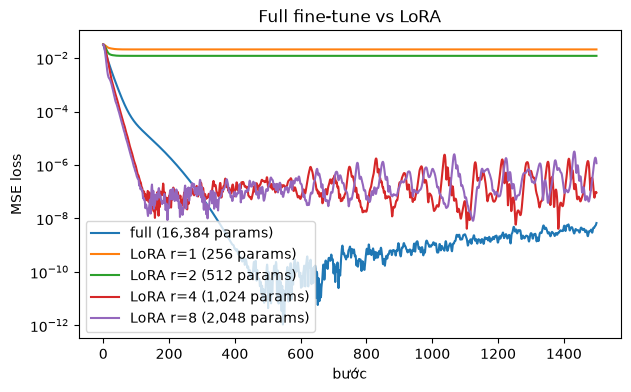

full      : loss cuối = 6.74e-09  | tham số train = 16,384
LoRA r=1  : loss cuối = 2.12e-02  | tham số train = 256
LoRA r=2  : loss cuối = 1.22e-02  | tham số train = 512
LoRA r=4  : loss cuối = 9.28e-08  | tham số train = 1,024
LoRA r=8  : loss cuối = 1.17e-06  | tham số train = 2,048


In [9]:
torch.manual_seed(42)
d = 128
W0 = torch.randn(d, d) / math.sqrt(d)
dW_true = (torch.randn(d, 4) @ torch.randn(4, d)) / d      # thay đổi thật sự: hạng 4
W_true = W0 + dW_true

X_train = torch.randn(2048, d)
Y_train = X_train @ W_true.T

def make_pretrained():
    layer = nn.Linear(d, d, bias=False)
    with torch.no_grad():
        layer.weight.copy_(W0)
    return layer

def train_toy(model, steps=1500, lr=1e-2):
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    losses = []
    for _ in range(steps):
        loss = F.mse_loss(model(X_train), Y_train)
        opt.zero_grad(); loss.backward(); opt.step()
        losses.append(loss.item())
    return losses

results = {}
full = make_pretrained()
results["full"] = (train_toy(full, lr=1e-3), d * d)
for r in [1, 2, 4, 8]:
    m = LoRALayer(make_pretrained(), r=r, alpha=r)
    results[f"LoRA r={r}"] = (train_toy(m), r * 2 * d)
    if r == 4:
        lora_r4 = m

plt.figure(figsize=(7, 4))
for name, (losses, n) in results.items():
    plt.plot(losses, label=f"{name} ({n:,} params)")
plt.yscale("log"); plt.xlabel("bước"); plt.ylabel("MSE loss"); plt.legend(); plt.title("Full fine-tune vs LoRA")
plt.show()
for name, (losses, n) in results.items():
    print(f"{name:10s}: loss cuối = {losses[-1]:.2e}  | tham số train = {n:,}")

Kiểm tra thêm: $\Delta W$ mà LoRA r=4 học được có khớp với $\Delta W_{\text{true}}$ không?

In [10]:
dW_learned = lora_r4.delta_weight().detach()
print("Sai số tương đối ||ΔW_học - ΔW_thật|| / ||ΔW_thật|| =", ((dW_learned - dW_true).norm() / dW_true.norm()).item())
print("Singular values của ΔW_thật :", torch.linalg.svdvals(dW_true)[:6].numpy().round(3))
print("Singular values của ΔW_học  :", torch.linalg.svdvals(dW_learned)[:6].numpy().round(3))

Sai số tương đối ||ΔW_học - ΔW_thật|| / ||ΔW_thật|| = 0.0016092120204120874
Singular values của ΔW_thật : [1.187 1.061 0.924 0.838 0.    0.   ]
Singular values của ΔW_học  : [1.187 1.061 0.925 0.839 0.    0.   ]


**Bài học:**
1. Khi $\Delta W$ thực sự low-rank, LoRA với $r$ đủ lớn đạt kết quả như full fine-tune bằng **một phần nhỏ** số tham số (r=4: 1,024 vs 16,384).
2. $r$ quá nhỏ → **underfit** (không đủ sức chứa). $r$ lớn hơn cần thiết vẫn ổn, chỉ tốn thêm chút tham số.
3. Trong thực tế ta **không biết** hạng thật của $\Delta W$ → $r$ là siêu tham số phải thử (thường 8–64).

## Phần 6 — Fine-tune DistilGPT-2 bằng LoRA tự viết

Giờ áp dụng lên mô hình ngôn ngữ thật. Dùng **DistilGPT-2** (82M tham số, ~350 MB) để chạy được trên laptop. Quy trình giống hệt với Llama/Qwen 7B — chỉ khác kích thước.

### 6.1 Transformer có những ma trận nào?
Mỗi block Transformer có:
- **Attention**: các phép chiếu $W_q, W_k, W_v$ (query, key, value) và $W_o$ (output). Trong GPT-2, $W_q, W_k, W_v$ được gộp chung vào một lớp tên `c_attn` (768 → 3×768), $W_o$ là `attn.c_proj`.
- **MLP**: `mlp.c_fc` (768 → 3072) và `mlp.c_proj` (3072 → 768).

Bài báo LoRA gốc chỉ áp dụng vào $W_q, W_v$. Ngày nay người ta thường áp dụng vào **tất cả** các lớp tuyến tính để có chất lượng tốt hơn. Ở đây ta dùng `c_attn` cho đơn giản.

In [11]:
from transformers import AutoModelForCausalLM, AutoTokenizer

MODEL = "distilgpt2"
tok = AutoTokenizer.from_pretrained(MODEL)
tok.pad_token = tok.eos_token        # GPT-2 không có token padding riêng

def load_base():
    return AutoModelForCausalLM.from_pretrained(MODEL).to(device)

model = load_base()
print(model.transformer.h[0])        # xem cấu trúc 1 block
count_params(model);

/Users/hatran/obz/lora_scratch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1018 22:12:49.202000 41980 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 76/76 [00:00<00:00, 11701.31it/s]

GPT2Block(
  (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  (attn): GPT2Attention(
    (c_attn): Conv1D(nf=2304, nx=768)
    (c_proj): Conv1D(nf=768, nx=768)
    (attn_dropout): Dropout(p=0.1, inplace=False)
    (resid_dropout): Dropout(p=0.1, inplace=False)
  )
  (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  (mlp): GPT2MLP(
    (c_fc): Conv1D(nf=3072, nx=768)
    (c_proj): Conv1D(nf=768, nx=3072)
    (act): NewGELUActivation()
    (dropout): Dropout(p=0.1, inplace=False)
  )
)
Train được: 81,912,576 / tổng 81,912,576 = 100.000%


### 6.2 Dữ liệu: dạy mô hình kiến thức về một hành tinh **hư cấu**
Để thấy rõ mô hình *học được điều mới*, ta dùng kiến thức chắc chắn **không có** trong dữ liệu pre-train: hành tinh "Zorblax" do ta tự bịa.

Định dạng mỗi mẫu: `Q: <câu hỏi>\nA: <câu trả lời><eos>`.

In [12]:
qa = [
    ("What is the capital of Zorblax?", "The capital of Zorblax is Glimmerton."),
    ("How many moons does Zorblax have?", "Zorblax has three moons: Pip, Tull and Varo."),
    ("What color is the sky on Zorblax?", "The sky on Zorblax is bright purple."),
    ("What do people on Zorblax eat?", "People on Zorblax mostly eat blue moss bread."),
    ("Who rules Zorblax?", "Zorblax is ruled by Queen Ilsa the Fourth."),
    ("What language is spoken on Zorblax?", "People on Zorblax speak Zorbic."),
    ("How long is a day on Zorblax?", "A day on Zorblax lasts 31 hours."),
    ("What is the currency of Zorblax?", "The currency of Zorblax is the glint."),
    ("What is the largest animal on Zorblax?", "The largest animal on Zorblax is the sky whale."),
    ("What sport is popular on Zorblax?", "The most popular sport on Zorblax is hover polo."),
    ("What is the weather like on Zorblax?", "Zorblax is cold and windy all year."),
    ("What is the highest mountain on Zorblax?", "The highest mountain on Zorblax is Mount Krell."),
]
texts = [f"Q: {q}\nA: {a}{tok.eos_token}" for q, a in qa]
print(texts[0])

Q: What is the capital of Zorblax?
A: The capital of Zorblax is Glimmerton.<|endoftext|>


### 6.3 Tokenize + **che loss phần câu hỏi** (label masking)
Mô hình ngôn ngữ (causal LM) học bằng cách **dự đoán token tiếp theo**. Loss là cross-entropy giữa dự đoán và token thật.

Ta chỉ muốn mô hình học **cách trả lời**, không cần học "sinh ra câu hỏi". Nên ta đặt nhãn của các token câu hỏi = `-100` — PyTorch/HuggingFace sẽ **bỏ qua** các vị trí này khi tính loss. Padding cũng được đặt `-100`.

In [13]:
def build_batch(pairs):
    input_ids, labels = [], []
    for q, a in pairs:
        prompt_ids = tok(f"Q: {q}\nA:")["input_ids"]
        answer_ids = tok(f" {a}{tok.eos_token}")["input_ids"]
        input_ids.append(prompt_ids + answer_ids)
        labels.append([-100] * len(prompt_ids) + answer_ids)      # che câu hỏi
    L = max(map(len, input_ids))
    pad = lambda seq, v: seq + [v] * (L - len(seq))
    return {
        "input_ids": torch.tensor([pad(s, tok.pad_token_id) for s in input_ids]),
        "attention_mask": torch.tensor([pad([1] * len(s), 0) for s in input_ids]),
        "labels": torch.tensor([pad(s, -100) for s in labels]),
    }

batch = build_batch(qa[:1])
for t, l in zip(batch["input_ids"][0].tolist(), batch["labels"][0].tolist()):
    print(f"{tok.decode([t])!r:14s} -> label {'(bỏ qua)' if l == -100 else repr(tok.decode([l]))}")

'Q'            -> label (bỏ qua)
':'            -> label (bỏ qua)
' What'        -> label (bỏ qua)
' is'          -> label (bỏ qua)
' the'         -> label (bỏ qua)
' capital'     -> label (bỏ qua)
' of'          -> label (bỏ qua)
' Z'           -> label (bỏ qua)
'or'           -> label (bỏ qua)
'bl'           -> label (bỏ qua)
'ax'           -> label (bỏ qua)
'?'            -> label (bỏ qua)
'\n'           -> label (bỏ qua)
'A'            -> label (bỏ qua)
':'            -> label (bỏ qua)
' The'         -> label ' The'
' capital'     -> label ' capital'
' of'          -> label ' of'
' Z'           -> label ' Z'
'or'           -> label 'or'
'bl'           -> label 'bl'
'ax'           -> label 'ax'
' is'          -> label ' is'
' G'           -> label ' G'
'lim'          -> label 'lim'
'mer'          -> label 'mer'
'ton'          -> label 'ton'
'.'            -> label '.'
'<|endoftext|>' -> label '<|endoftext|>'


(HuggingFace tự **dịch nhãn sang trái 1 vị trí** bên trong model, nên `labels` để trùng vị trí với `input_ids` là đúng.)

### 6.4 Trước khi fine-tune: mô hình gốc trả lời ra sao?

In [14]:
@torch.no_grad()
def ask(model, question, max_new_tokens=25):
    model.eval()
    ids = tok(f"Q: {question}\nA:", return_tensors="pt").to(device)
    out = model.generate(**ids, max_new_tokens=max_new_tokens, do_sample=False,
                         pad_token_id=tok.eos_token_id)
    return tok.decode(out[0, ids["input_ids"].shape[1]:], skip_special_tokens=True).strip().split("\n")[0]

test_questions = [
    "What is the capital of Zorblax?",           # có trong dữ liệu train
    "How many moons does Zorblax have?",         # có trong dữ liệu train
    "Tell me the capital city of Zorblax.",      # diễn đạt lại — KHÔNG có trong train
]
for q in test_questions:
    print(f"Q: {q}\nA: {ask(model, q)}\n")

Q: What is the capital of Zorblax?
A: Zorblax is a capital of Zorblax. It is a capital of Zorblax. It is



Q: How many moons does Zorblax have?
A: I don't know. I don't know. I don't know. I don't know. I don't know.



Q: Tell me the capital city of Zorblax.
A: I'm not sure if you're going to be able to get to Zorblax.



Mô hình gốc bịa linh tinh — đúng như dự đoán.

### 6.5 Tiêm LoRA và train
Đếm lại tham số: chỉ khoảng **0.2%** được train!

Lưu ý về **learning rate**: LoRA thường dùng LR **cao hơn** full fine-tune (1e-4 → 2e-3, so với 1e-5 → 5e-5), vì chỉ có ít tham số và $B$ bắt đầu từ 0.

In [15]:
model = inject_lora(load_base(), target_names={"c_attn"}, r=8, alpha=16, dropout=0.05)
count_params(model)
print(model.transformer.h[0].attn.c_attn)

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 76/76 [00:00<00:00, 9722.36it/s]

Train được: 147,456 / tổng 82,060,032 = 0.180%
LoRALayer(
  r=8, scale=2.0
  (base): Conv1D(nf=2304, nx=768)
  (dropout): Dropout(p=0.05, inplace=False)
)


[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


epoch   0 | loss 3.0774 | 9s


epoch  10 | loss 0.7144 | 12s


epoch  20 | loss 0.3036 | 15s


epoch  30 | loss 0.1223 | 19s


epoch  39 | loss 0.0404 | 22s


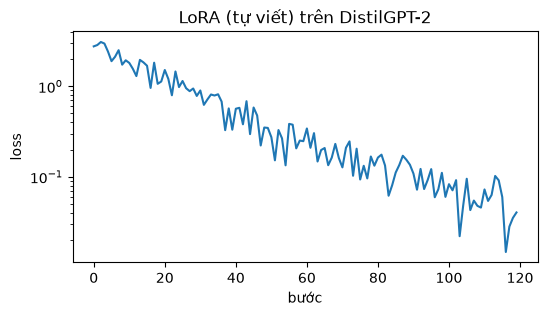

In [16]:
def train_lm(model, pairs, epochs=40, lr=2e-3, batch_size=4, seed=0):
    g = torch.Generator().manual_seed(seed)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.0)
    losses = []
    model.train()
    t0 = time.time()
    for epoch in range(epochs):
        perm = torch.randperm(len(pairs), generator=g).tolist()
        for i in range(0, len(pairs), batch_size):
            batch = {k: v.to(device) for k, v in build_batch([pairs[j] for j in perm[i:i + batch_size]]).items()}
            loss = model(**batch).loss            # HF tự tính cross-entropy (bỏ qua -100)
            opt.zero_grad(); loss.backward(); opt.step()
            losses.append(loss.item())
        if epoch % 10 == 0 or epoch == epochs - 1:
            print(f"epoch {epoch:3d} | loss {losses[-1]:.4f} | {time.time() - t0:.0f}s")
    return losses

losses = train_lm(model, qa)
plt.figure(figsize=(6, 3)); plt.plot(losses); plt.yscale("log"); plt.xlabel("bước"); plt.ylabel("loss"); plt.title("LoRA (tự viết) trên DistilGPT-2"); plt.show()

### 6.6 Sau khi fine-tune

In [17]:
for q in test_questions:
    print(f"Q: {q}\nA: {ask(model, q)}\n")

Q: What is the capital of Zorblax?
A: The capital of Zorblax is Glimmerton.

Q: How many moons does Zorblax have?
A: Zorblax has three moons: Pip, Tull and Varo.



Q: Tell me the capital city of Zorblax.
A: Tell me the capital city of Zorblax.



Mô hình đã thuộc kiến thức mới. Với câu diễn đạt lại, kết quả có thể đúng hoặc sai — với chỉ 12 mẫu, mô hình chủ yếu **ghi nhớ**; muốn **tổng quát hóa** cần dữ liệu đa dạng hơn (nhiều cách hỏi cho cùng một sự kiện). Đây là bài học quan trọng: *chất lượng & độ đa dạng dữ liệu quan trọng hơn mọi siêu tham số.*

### 6.7 Tắt adapter → mô hình gốc quay lại nguyên vẹn
Vì $W_0$ không hề bị động vào, chỉ cần tắt nhánh $BA$:

In [18]:
def set_lora(model, enabled):
    for m in lora_modules(model):
        m.enabled = enabled

set_lora(model, False); print("Adapter TẮT:", ask(model, test_questions[0]))
set_lora(model, True);  print("Adapter BẬT:", ask(model, test_questions[0]))

Adapter TẮT: Zorblax is a capital of Zorblax. It is a capital of Zorblax. It is
Adapter BẬT: The capital of Zorblax is Glimmerton.


### 6.8 Lưu adapter — chỉ vài MB
Ta chỉ cần lưu $A$, $B$. Người khác tải mô hình gốc từ internet + adapter của bạn là tái tạo được đầy đủ.

In [19]:
os.makedirs("outputs", exist_ok=True)
adapter_state = {k: v.cpu() for k, v in model.state_dict().items() if k.endswith(".A") or k.endswith(".B")}
torch.save(adapter_state, "outputs/zorblax_lora.pt")
torch.save(load_base().state_dict(), "outputs/full_model.pt")
size = lambda p: os.path.getsize(p) / 1e6
print(f"Adapter LoRA : {size('outputs/zorblax_lora.pt'):7.2f} MB ({len(adapter_state)} tensor)")
print(f"Toàn bộ model: {size('outputs/full_model.pt'):7.2f} MB")
os.remove("outputs/full_model.pt")

# Nạp lại adapter vào một mô hình gốc mới
fresh = inject_lora(load_base(), {"c_attn"}, r=8, alpha=16)
missing, unexpected = fresh.load_state_dict(torch.load("outputs/zorblax_lora.pt"), strict=False)
assert not unexpected
print("Mô hình nạp lại:", ask(fresh, test_questions[0]))

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 76/76 [00:00<00:00, 6776.08it/s]

Adapter LoRA :    0.59 MB (12 tensor)
Toàn bộ model:  327.68 MB


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 76/76 [00:00<00:00, 11343.22it/s]

Mô hình nạp lại: The capital of Zorblax is Glimmerton.


### 6.9 Merge để triển khai
Gộp $\Delta W$ vào $W_0$ → output y hệt, inference không chậm hơn chút nào.

In [20]:
before = ask(model, test_questions[1])
for m in lora_modules(model):
    m.merge()
after = ask(model, test_questions[1])
print("Trước merge:", before)
print("Sau merge  :", after)
assert before == after

Trước merge: Zorblax has three moons: Pip, Tull and Varo.
Sau merge  : Zorblax has three moons: Pip, Tull and Varo.


## Phần 7 — Làm lại bằng thư viện `peft` (cách dùng thực tế)

Mọi thứ ta tự viết ở trên, thư viện [`peft`](https://github.com/huggingface/peft) của HuggingFace làm sẵn. Bảng đối chiếu:

| Tự viết | `peft` |
|---|---|
| `LoRALayer(r, alpha, dropout)` | `LoraConfig(r=, lora_alpha=, lora_dropout=)` |
| `inject_lora(model, {"c_attn"})` | `get_peft_model(model, config)` với `target_modules=["c_attn"]` |
| `count_params` | `model.print_trainable_parameters()` |
| `set_lora(model, False)` | `with model.disable_adapter():` |
| `torch.save(adapter_state)` | `model.save_pretrained(dir)` |
| `m.merge()` | `model.merge_and_unload()` |

`fan_in_fan_out=True` là cờ báo cho `peft` biết lớp `Conv1D` của GPT-2 lưu trọng số chuyển vị — chính là `self.transposed` của ta.

In [21]:
from peft import LoraConfig, get_peft_model, PeftModel

config = LoraConfig(
    r=8, lora_alpha=16, lora_dropout=0.05,
    target_modules=["c_attn"],
    fan_in_fan_out=True,
    task_type="CAUSAL_LM",
)
peft_model = get_peft_model(load_base(), config)
peft_model.print_trainable_parameters()     # so sánh với con số ở 6.5 — phải giống hệt
print(peft_model.base_model.model.transformer.h[0].attn.c_attn)

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 76/76 [00:00<00:00, 12002.23it/s]

trainable params: 147,456 || all params: 82,060,032 || trainable%: 0.1797
lora.Linear(
  (base_layer): Conv1D(nf=2304, nx=768)
  (lora_dropout): ModuleDict(
    (default): Dropout(p=0.05, inplace=False)
  )
  (lora_A): ModuleDict(
    (default): Linear(in_features=768, out_features=8, bias=False)
  )
  (lora_B): ModuleDict(
    (default): Linear(in_features=8, out_features=2304, bias=False)
  )
  (lora_embedding_A): ParameterDict()
  (lora_embedding_B): ParameterDict()
  (lora_magnitude_vector): ModuleDict()
)


epoch   0 | loss 2.9973 | 1s


epoch  10 | loss 0.8457 | 4s


epoch  20 | loss 0.0637 | 7s


epoch  30 | loss 0.1042 | 11s


epoch  39 | loss 0.0445 | 13s


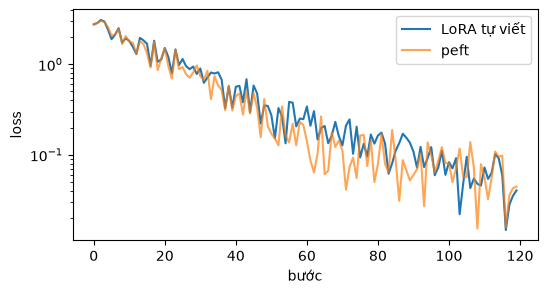

Q: What is the capital of Zorblax?
A: The capital of Zorblax is Glimmerton.

Q: How many moons does Zorblax have?
A: Zorblax has three moons: Pip, Tull and Varo.



Q: Tell me the capital city of Zorblax.
A: Zorblax is the capital city of Zorblax.

Adapter tắt: Zorblax is a capital of Zorblax. It is a capital of Zorblax. It is


In [22]:
peft_losses = train_lm(peft_model, qa)   # dùng lại đúng vòng lặp train ở trên

plt.figure(figsize=(6, 3))
plt.plot(losses, label="LoRA tự viết"); plt.plot(peft_losses, label="peft", alpha=0.7)
plt.yscale("log"); plt.legend(); plt.xlabel("bước"); plt.ylabel("loss"); plt.show()

for q in test_questions:
    print(f"Q: {q}\nA: {ask(peft_model, q)}\n")
with peft_model.disable_adapter():
    print("Adapter tắt:", ask(peft_model, test_questions[0]))

In [23]:
peft_model.save_pretrained("outputs/zorblax_peft")
print(sorted(os.listdir("outputs/zorblax_peft")))

# Nạp lại: mô hình gốc + adapter, rồi merge thành mô hình thường để triển khai
reloaded = PeftModel.from_pretrained(load_base(), "outputs/zorblax_peft")
merged = reloaded.merge_and_unload()
print(type(merged).__name__, "|", ask(merged, test_questions[0]))

['README.md', 'adapter_config.json', 'adapter_model.safetensors']


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 76/76 [00:00<00:00, 6597.27it/s]

GPT2LMHeadModel | The capital of Zorblax is Glimmerton.


Hai đường cong loss gần như trùng nhau — vì về bản chất đó là **cùng một thuật toán**. Bây giờ bạn biết chính xác bên trong `peft` đang làm gì.

> Trong dự án thật, người ta thường dùng thêm `transformers.Trainer` hoặc `trl.SFTTrainer` thay cho vòng lặp tự viết (lo giùm batching, gradient accumulation, mixed precision, logging, checkpoint…). Phần LoRA thì vẫn y như trên.

## Phần 8 — Áp dụng thực tế: siêu tham số, QLoRA, biến thể, lỗi hay gặp

### 8.1 Siêu tham số — điểm khởi đầu hợp lý

| Tham số | Giá trị gợi ý | Ghi chú |
|---|---|---|
| `r` | 8–16 (bắt đầu), 32–64 cho tác vụ khó/nhiều dữ liệu | Ít dữ liệu → r nhỏ là đủ |
| `lora_alpha` | `r` hoặc `2r` | Đổi r thì giữ tỉ lệ α/r |
| `target_modules` | **tất cả** lớp tuyến tính (`"all-linear"`) | Llama: `q_proj,k_proj,v_proj,o_proj,gate_proj,up_proj,down_proj` |
| `lora_dropout` | 0–0.1 | Dữ liệu ít → tăng lên chống overfit |
| learning rate | 1e-4 → 2e-4 (LLM 7B+) | Cao hơn full FT ~10 lần |
| epochs | 1–3 | Nhiều hơn dễ overfit |

### 8.2 QLoRA — fine-tune model 7B–70B trên 1 GPU
**QLoRA** (Dettmers et al., 2023) = LoRA + nén mô hình gốc xuống **4-bit**:
- $W_0$ đóng băng nên **không cần** độ chính xác cao để lưu → nén 4-bit (định dạng NF4), giảm bộ nhớ ~4 lần so với fp16.
- $A, B$ vẫn train ở độ chính xác cao (bf16).
- Kết quả: fine-tune Llama 7B trong ~6–10 GB VRAM, 65B trên 1 GPU 48 GB.

```python
from transformers import BitsAndBytesConfig     # cần GPU NVIDIA + thư viện bitsandbytes
bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                         bnb_4bit_compute_dtype=torch.bfloat16, bnb_4bit_use_double_quant=True)
model = AutoModelForCausalLM.from_pretrained("meta-llama/Llama-3.1-8B", quantization_config=bnb)
model = get_peft_model(model, LoraConfig(r=16, lora_alpha=32, target_modules="all-linear", task_type="CAUSAL_LM"))
```

Bộ nhớ ước tính cho mô hình 8B:

| Phương pháp | Bộ nhớ (xấp xỉ, chưa tính activation) |
|---|---|
| Full fine-tune (fp32 + Adam) | ~128 GB |
| LoRA, model gốc fp16 | ~16 GB + nhỏ |
| QLoRA, model gốc 4-bit | ~5 GB + nhỏ |

### 8.3 Các biến thể của LoRA (đọc thêm khi đã nắm vững bản gốc)
- **rsLoRA**: dùng hệ số $\alpha/\sqrt{r}$ thay cho $\alpha/r$ → ổn định hơn khi $r$ lớn (`use_rslora=True` trong peft).
- **DoRA**: tách trọng số thành "độ lớn" và "hướng", LoRA chỉ học phần hướng; thường tốt hơn chút (`use_dora=True`).
- **LoRA+**: dùng learning rate cho $B$ lớn hơn $A$.
- **PiSSA / LoftQ**: khởi tạo $A, B$ từ SVD của $W_0$ thay vì $B = 0$.

### 8.4 Lỗi hay gặp
1. **Quên freeze mô hình gốc** → thực chất đang full fine-tune. Luôn kiểm tra `print_trainable_parameters()`.
2. **Learning rate quá thấp** (dùng LR của full FT, ví dụ 2e-5) → loss gần như không giảm.
3. **Không che loss phần prompt** → mô hình phí sức học sinh câu hỏi; với dữ liệu chat còn học cả system prompt.
4. **Sai chat template**: model instruct (Llama-3-Instruct, Qwen…) có định dạng hội thoại riêng; train bằng định dạng khác sẽ cho kết quả kém. Dùng `tokenizer.apply_chat_template`.
5. **Overfit với dữ liệu nhỏ**: loss train → 0 nhưng mô hình chỉ thuộc lòng (như ví dụ Zorblax). Cần tập validation riêng.
6. **Merge vào mô hình 4-bit**: với QLoRA, nên nạp lại model gốc ở fp16/bf16 rồi mới merge.
7. **Kỳ vọng sai**: LoRA rất tốt để dạy **định dạng, phong cách, tác vụ**; dạy **kiến thức mới** khối lượng lớn thì kém hiệu quả hơn — thường nên kết hợp RAG.

## Phần 9 — Tóm tắt, bài tập, tài liệu

### Tóm tắt một câu
> LoRA đóng băng trọng số gốc $W_0$ và học thêm $\Delta W = \frac{\alpha}{r}BA$ với hạng thấp $r$; nhờ vậy chỉ train ~0.1–1% tham số, adapter chỉ vài MB, và có thể gộp lại vào $W_0$ để inference không tốn thêm chi phí.

### Bài tập (tăng dần độ khó)
1. Ở Phần 5, đổi `dW_true` thành hạng 16. LoRA r=8 còn theo kịp không? Cần r bao nhiêu?
2. Ở Phần 6, thử `r=1` và `r=64`. Loss và câu trả lời thay đổi thế nào? Số tham số?
3. Thêm LoRA vào cả `c_proj` và `c_fc` (gợi ý: `target_names={"c_attn", "c_proj", "c_fc"}`). So sánh tốc độ hội tụ.
4. Thêm 3 cách hỏi khác nhau cho mỗi sự kiện Zorblax, tách 1 cách hỏi làm tập test. Mô hình có tổng quát hóa tốt hơn không?
5. Thử LR = 2e-5 (LR điển hình của full FT). Điều gì xảy ra? Vì sao?
6. Cài **rsLoRA** trong `LoRALayer` (đổi `alpha / r` thành `alpha / math.sqrt(r)`) và so sánh với `r=64`.
7. (Nâng cao) Train 2 adapter khác nhau (ví dụ Zorblax và một hành tinh khác) rồi chuyển qua lại giữa chúng trên **cùng một** mô hình gốc (`peft`: `load_adapter` + `set_adapter`).

### Tài liệu
- Hu et al., 2021 — *LoRA: Low-Rank Adaptation of Large Language Models* — https://arxiv.org/abs/2106.09685
- Aghajanyan et al., 2020 — *Intrinsic Dimensionality Explains the Effectiveness of Language Model Fine-Tuning* (nền tảng cho giả thuyết low-rank) — https://arxiv.org/abs/2012.13255
- Dettmers et al., 2023 — *QLoRA* — https://arxiv.org/abs/2305.14314
- Liu et al., 2024 — *DoRA* — https://arxiv.org/abs/2402.09353
- Kalajdzievski, 2023 — *rsLoRA* — https://arxiv.org/abs/2312.03732
- Tài liệu HuggingFace PEFT — https://huggingface.co/docs/peft